In [30]:
import numpy as np
import config
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from scipy.stats import spearmanr

from get_data import DataLoader

# Load data
DataLoader = DataLoader(config.DATA_PATH)
df = DataLoader.load_data()
df_cor = df[['year', 'pm25_concentration']].dropna()

### Show the two variables in a plot

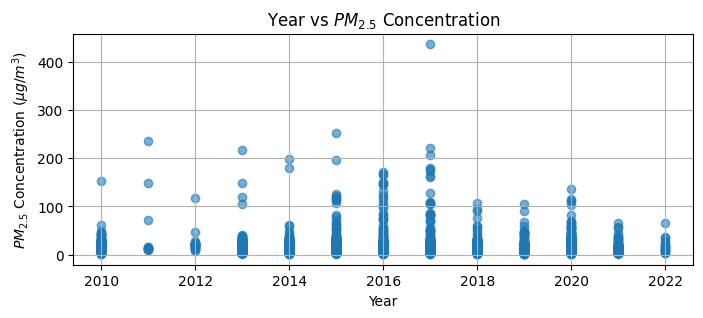

<Figure size 640x480 with 0 Axes>

In [48]:
# Create a scatterplot between year and pm25_concentration
plt.figure(figsize=(8, 3))
plt.scatter(df['year'], df['pm25_concentration'], alpha=0.6)
plt.title('Year vs $PM_{2.5}$ Concentration')
plt.xlabel('Year')
plt.ylabel('$PM_{2.5}$ Concentration ($\\mu g/m^3$)')
plt.grid(True)
plt.show()
plt.savefig('q3_year_vs_pm25.png', dpi=300, bbox_inches='tight')

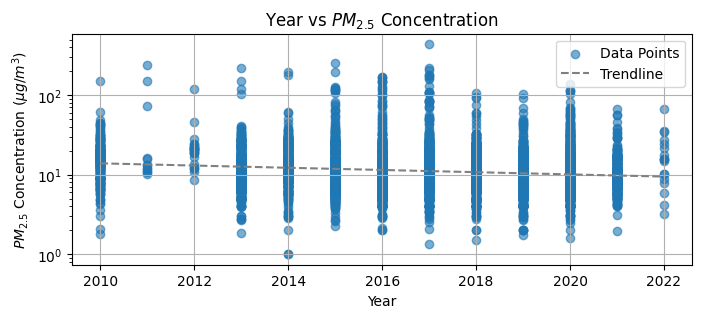

In [49]:
plt.figure(figsize=(8, 3))
plt.scatter(df_cor['year'], df_cor['pm25_concentration'], alpha=0.6, label='Data Points')

log_pm25 = np.log(df_cor['pm25_concentration'])
slope, intercept = np.polyfit(df_cor['year'], log_pm25, 1)

years_fit = np.linspace(df_cor['year'].min(), df_cor['year'].max(), 100)
pm25_fit = np.exp(intercept + slope * years_fit)

plt.plot(years_fit, pm25_fit, color='gray', linestyle='--', label='Trendline')

plt.title('Year vs $PM_{2.5}$ Concentration')
plt.xlabel('Year')
plt.ylabel('$PM_{2.5}$ Concentration ($\\mu g/m^3$)')
plt.yscale('log')  
plt.grid(True)
plt.legend()
plt.savefig('q3_year_vs_pm25log.png', dpi=300, bbox_inches='tight')
plt.show()


### Are the data normally distributed?
I used the Shapiro Wilk test to determine normality.

* $H_0$: population is normally distributed.
* $H_A$: population is not normally distributed.


Both $p$ values are very small (<0.05), therefore reject $H_0$. Data is not normally distributed. Logically, years are ordinal data. Therefore testing for it is not needed.

In [33]:
years = df_cor['year']
sample_years = years.sample(n=5000, random_state=42)
pm25  = df_cor['pm25_concentration']
sample_pm25 = pm25.sample(n=5000, random_state=42)

shapiro_y = shapiro(sample_years)
shapiro_p = shapiro(sample_pm25)

print(f"Shapiro-Wilk test for years: W={shapiro_y.statistic}, p-value={shapiro_y.pvalue}")
print(f"Shapiro-Wilk test for pm25:  W={shapiro_p.statistic}, p-value={shapiro_p.pvalue}")

Shapiro-Wilk test for years: W=0.9487614907205778, p-value=1.2664931563358158e-38
Shapiro-Wilk test for pm25:  W=0.4172506963863445, p-value=1.702281488611374e-83


Spearman rank correlation ($\rho$) can be used:
* The two variables are not normally distributed
* The variables are continuous
* The relationship is monotonic

### Run the test

In [36]:
# Run Spearman's correlation
spearman_corr, spearman_pval = spearmanr(years, pm25)

print(f"Spearman's correlation: {spearman_corr}")
print(f"P-value: {spearman_pval}")

Spearman's correlation: -0.16378897066391207
P-value: 7.303773567881984e-39
